# 01 · 数据范围、质量与样本划分

本页读取已保存的 JSON、CSV 和图片，并进行展示专用的格式化、整合与排版。计算、抽样、划分核验与结果写入由 `criteo_uplift` 和主运行流程完成；修改本页的标题、选列或样式不会回写实验产物。

阅读顺序：**分析边界 → 数据质量 → 全量与抽样构成 → 样本划分 → 重叠检查**。表头与类别使用英文，说明和代码注释使用中文。

In [1]:
# 选择已有实验结果：优先本地；设置 CRITEO_RESULTS_MODE=published 可只读公开快照。
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, HTML

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "criteo_uplift").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from criteo_uplift.pipeline_io import result_directory

RUN = result_directory("conversion_1000000_seed42", ROOT)
manifest = json.loads((RUN / "manifest.json").read_text())
print("结果来源：", RUN.relative_to(ROOT))
# 只定义展示样式，不计算统计量、不写入项目结果。
TABLE_STYLES = [
    {"selector": "", "props": [("border-collapse", "collapse"), ("font-size", "14px"), ("min-width", "640px")]},
    {"selector": "th", "props": [("background-color", "#edf3f8"), ("color", "#18364b"), ("padding", "10px 14px"), ("text-align", "right"), ("border-bottom", "2px solid #b9cddd")]},
    {"selector": "td", "props": [("padding", "9px 14px"), ("text-align", "right"), ("border-bottom", "1px solid #e3eaf0")]},
    {"selector": "tbody tr:nth-child(even)", "props": [("background-color", "#f7fafc")]},
    {"selector": "td:first-child, th:first-child", "props": [("text-align", "left")]},
]

结果来源： artifacts/conversion_1000000_seed42


## 1. 数据集

- **f0–f11**：12 个匿名处理前特征，作为模型输入。
- **treatment**：处理分配；不等于实际广告曝光。
- **conversion / visit**：结果指标；**exposure** 仅用于审计，不加入模型特征，也不用于筛选人群。

公开数据不含可靠用户标识。`row_id` 标识原 CSV 的来源行，不代表用户身份；本页的数量均为行数。当前结果针对公开样本的分配效果，不直接等于线上曝光效果或收益。

In [2]:
# 只读取审计与抽样说明；本页不加载原始 CSV 或样本缓存。
audit = json.loads((RUN / "data_preparation/audit.json").read_text())
sample_report = json.loads((RUN / "data_preparation/sample_report.json").read_text())
print("分析指标：", manifest["primary_outcome"], "｜抽样随机种子：", sample_report["seed"])
print("抽样方法：", {"all rows": "保留全部来源行", "uniform without replacement, random-priority reservoir": "均匀无放回抽样（随机优先级蓄水池）"}.get(sample_report["sampling"], sample_report["sampling"]))
print("建模特征精度：", sample_report["feature_representation"], "｜原始字段数：", audit["n_columns"])

分析指标： conversion ｜抽样随机种子： 42
抽样方法： 均匀无放回抽样（随机优先级蓄水池）
建模特征精度： float32 ｜原始字段数： 16


## 2. 全量数据质量：有没有基础异常？

只展示缺失、非法标签和标签逻辑异常。以下计数直接来自全量审计；缺失与非法标签按单元格计数，逻辑异常按行计数。

In [3]:
# 每个检查只展示一次；保留原始计数，不在 Notebook 中重做校验。
quality_fields = {
    "missing_or_nonfinite": "Missing / non-finite values",
    "invalid_binary_labels": "Invalid binary-label values",
    "control_exposed": "Control rows with exposure",
    "conversion_without_visit": "Conversions without visit",
}
quality_table = pd.DataFrame([
    {"Check": label, "Count": audit[key]} for key, label in quality_fields.items()
])
display(quality_table.style.hide(axis="index").format({"Count": "{:,.0f}"}).set_table_styles(TABLE_STYLES))


Check,Count
Missing / non-finite values,0
Invalid binary-label values,0
Control rows with exposure,0
Conversions without visit,0


### 完整记录重复指纹：多余行数与分母

重复指纹使用原始精度下的完整记录字段，属于内容重复候选，不能证明同一用户重复出现，也不据此自动删除。全量内部的内容重复与后文的跨集合特征匹配是不同检查。

同一指纹出现 k 次只计 k−1 个多余行，不能把这个数理解成“唯一重复记录种数”。具体计数定义、分母和指纹局限直接来自审计文件。

In [4]:
# 直接读取审计字段；比例和方法说明由扫描阶段生成。
duplicate_table = pd.DataFrame([
    {"Item": "Full source rows", "Value": f"{audit['n_rows']:,}"},
    {"Item": "Excess fingerprint rows", "Value": f"{audit['duplicate_row_fingerprints']:,}"},
    {"Item": "Excess fraction", "Value": f"{audit['duplicate_row_fraction']:.2%}"},
    {"Item": "Fraction denominator (rows)", "Value": f"{audit['duplicate_fraction_denominator']:,}"},
    {"Item": "Count definition", "Value": audit["duplicate_count_definition"]},
    {"Item": "Fingerprint method / limitations", "Value": audit["duplicate_method"]},
])
display(duplicate_table.style.hide(axis="index").set_table_styles(TABLE_STYLES).set_properties(
    subset=["Value"], **{"text-align": "left", "white-space": "normal", "max-width": "620px", "overflow-wrap": "anywhere"}
))


Item,Value
Full source rows,"13,979,592"
Excess fingerprint rows,"1,259,545"
Excess fraction,9.01%
Fraction denominator (rows),"13,979,592"
Count definition,多余行数 = 全量行数 - 不同完整行指纹数；同一指纹出现 k 次贡献 k-1 行。不是出现重复的不同记录种数，也不是所有参与重复的行数；比例分母为全量原始记录数。
Fingerprint method / limitations,对原始 CSV 的全部 16 个字段按 float64 表示，使用 pandas.util.hash_pandas_object(index=False) 生成 uint64 指纹，并跨全部分块统计不同指纹数。64 位哈希存在碰撞可能，float64 解析也不等于原始文本逐字节相等；仅识别内容重复候选。没有可靠用户标识，不能证明同一用户重复出现，不据此自动删除记录。


## 3. 全量与建模样本：分组不均衡与稀疏转化

用一张对照表回答两个问题：处理／对照比例有多不均衡，转化事件有多稀少。`Share` 的分母为所在数据集总行数；`Conversion rate` 的分母为该组行数。全量和建模样本各自的 `Total` 已由计算阶段保存。

主流程按块扫描原始 CSV，统一准备全量审计、建模抽样和诊断统计。建模样本采用随机优先级蓄水池的均匀无放回抽样；C2ST 则独立按组等量抽样，用来比较两组特征分布。建模样本缓存与全量审计缓存分别核验来源和配置。原始统计使用 float64，建模特征缓存使用 float32 以降低内存；两者用途和重叠检查口径需要区分。

In [5]:
# 仅拼接两份现成汇总；组别标签由数据生成阶段统一。
group_table = pd.concat([
    pd.DataFrame(report["group_summary"]).assign(Dataset=label)
    for label, report in (("Full source", audit), ("Modeling sample", sample_report))
], ignore_index=True)
group_table = group_table[["Dataset", "group", "n", "fraction", "conversion_positive", "conversion_rate"]].rename(columns={
    "group": "Group", "n": "Rows", "fraction": "Share",
    "conversion_positive": "Conversions", "conversion_rate": "Conversion rate",
})
display(group_table.style.hide(axis="index").format({
    "Rows": "{:,.0f}", "Share": "{:.2%}", "Conversions": "{:,.0f}", "Conversion rate": "{:.4%}",
}, na_rep="—").set_table_styles(TABLE_STYLES).set_properties(subset=["Conversion rate"], **{"font-weight": "600", "color": "#175c83"}))

Dataset,Group,Rows,Share,Conversions,Conversion rate
Full source,Control,"2,096,937",15.00%,"4,063",0.1938%
Full source,Treatment,"11,882,655",85.00%,"36,711",0.3089%
Full source,Total,"13,979,592",100.00%,"40,774",0.2917%
Modeling sample,Control,"149,589",14.96%,273,0.1825%
Modeling sample,Treatment,"850,411",85.04%,"2,609",0.3068%
Modeling sample,Total,"1,000,000",100.00%,"2,882",0.2882%


### 建模特征分布

下图读取运行阶段保存的图片，展示各匿名特征的取值分布；纵轴使用对数刻度。本页不重新加载百万行样本或执行直方图分箱。处理组与对照组的 SMD／KS 检查统一放在 [Notebook 02](02_sanity_and_ate.ipynb)。

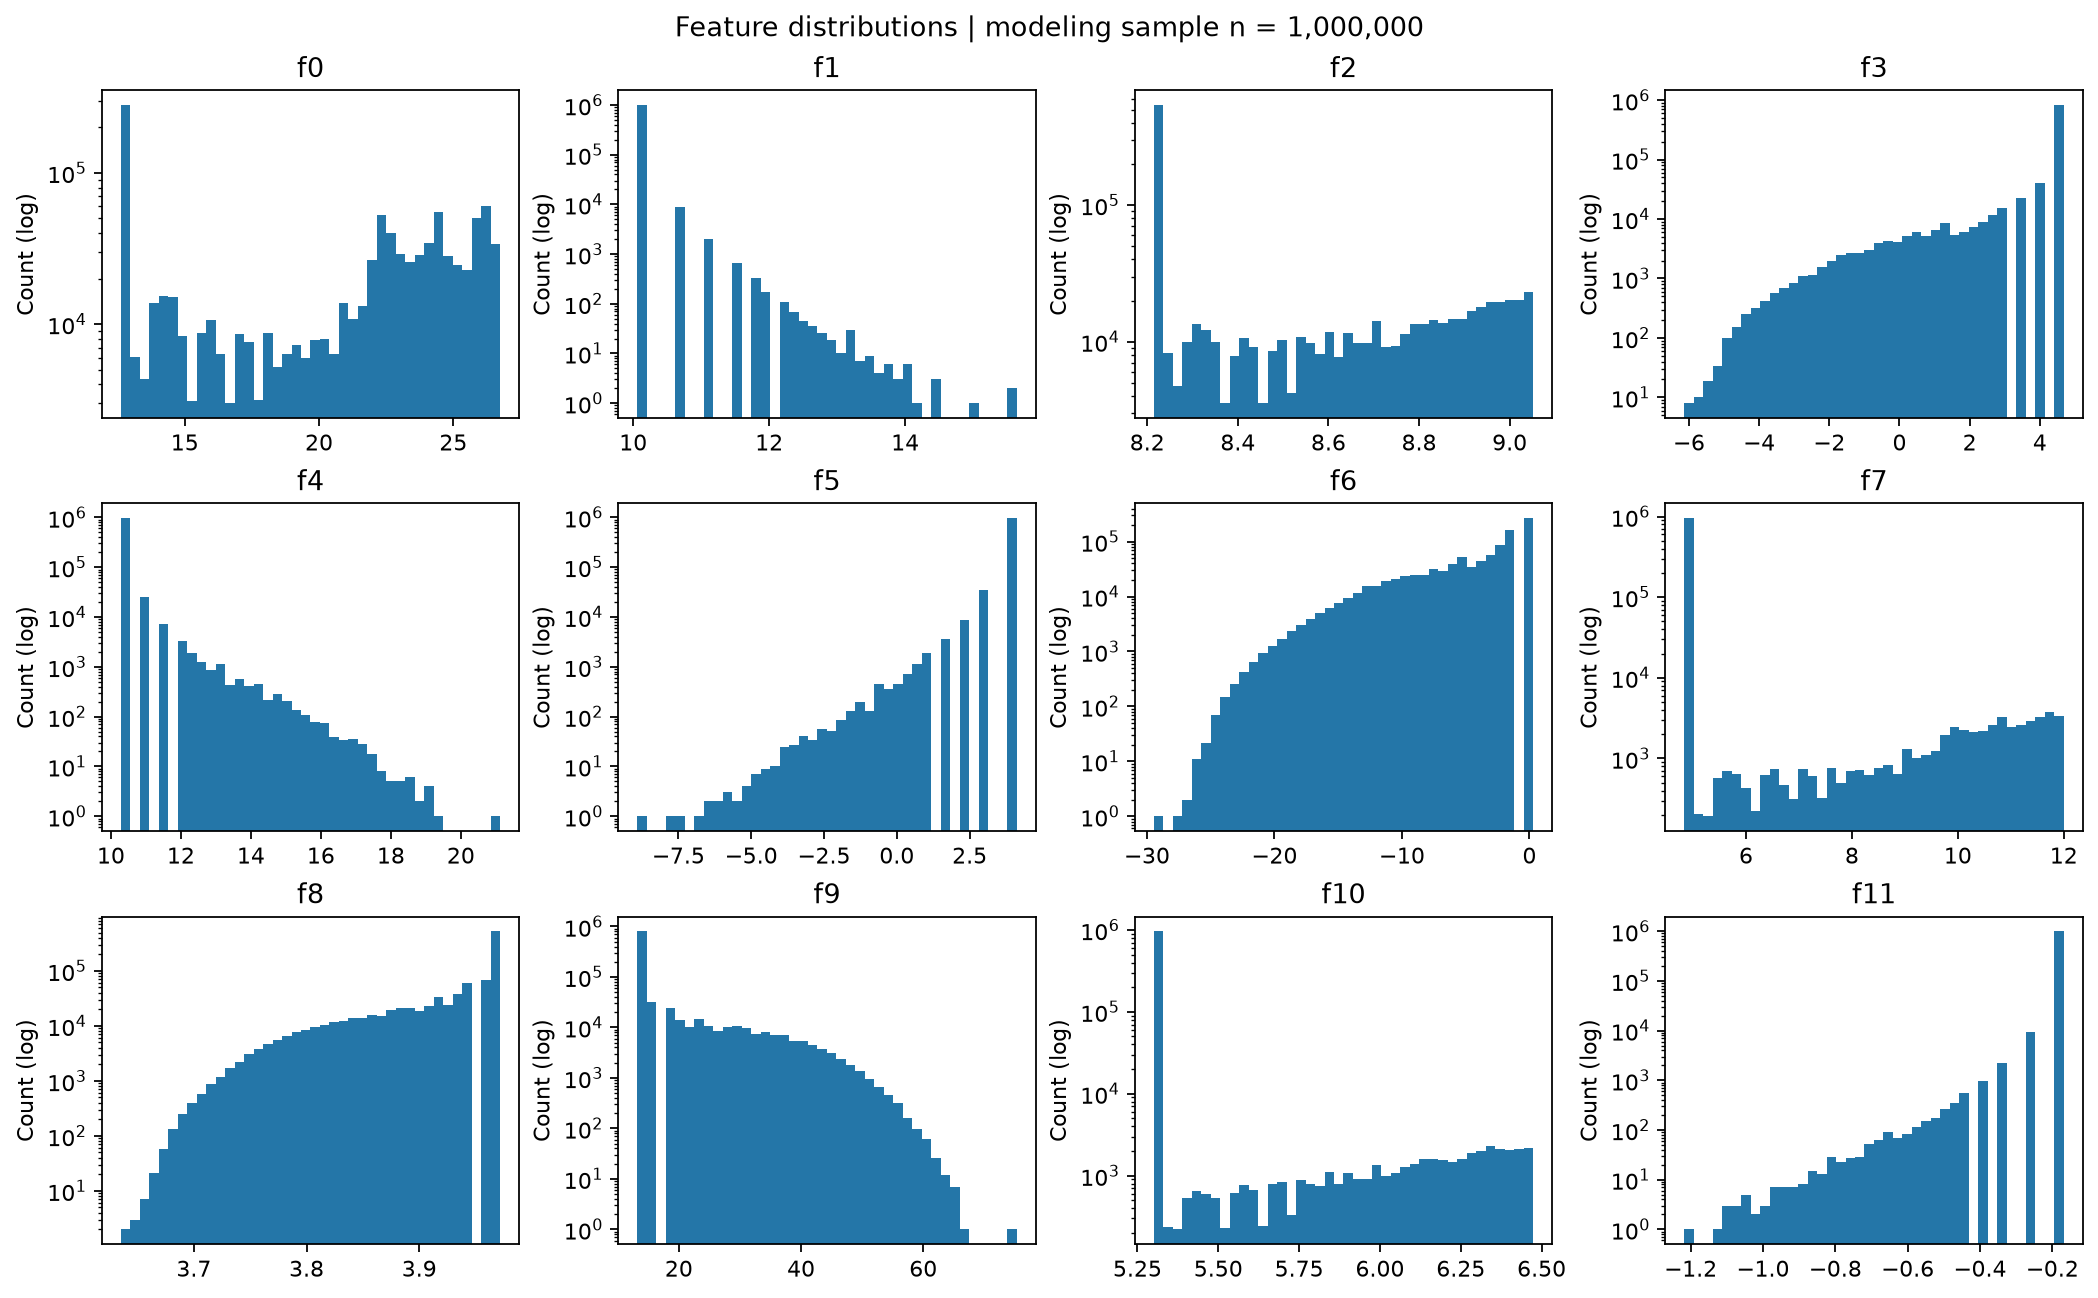

In [6]:
# 只显示当前实验的图片；缺失时明确提示，不自动计算或借用其他实验的结果。
feature_plot = RUN / "figures/sample_features.png"
if feature_plot.is_file():
    display(Image(filename=str(feature_plot)))
else:
    print("该实验尚未保存特征分布图；本页跳过此图，不触发计算。")

## 4. 样本划分：各集合是否保留足够事件？

主流程按 `treatment × 主结果` 联合分层，划分训练／验证／测试集（60%／20%／20%）。下表只展示各集合、各组的规模和事件数，不重复总体占比与转化率。

训练集用于拟合，验证集用于选择，测试集用于冻结后的独立评价；本页不重新划分数据。

In [7]:
# 展示已保存的划分汇总；隐藏 DataFrame 默认索引。
split_table = pd.read_csv(RUN / "data_preparation/split_summary.csv")
split_table = split_table.rename(columns={
    "split": "Split", "treatment": "Group", "n": "Rows",
    "conversion_positive": "Conversions", "visit_positive": "Visits",
})
split_table["Split"] = split_table["Split"].replace({"train": "Train", "validation": "Validation", "test": "Test"})
split_table["Group"] = split_table["Group"].replace({0: "Control", 1: "Treatment"})
display(split_table.style.hide(axis="index").format({
    "Rows": "{:,.0f}", "Conversions": "{:,.0f}", "Visits": "{:,.0f}",
}, na_rep="—").set_table_styles(TABLE_STYLES))

Split,Group,Rows,Conversions,Visits
Train,Control,"89,754",164,"3,372"
Train,Treatment,"510,246","1,565","24,685"
Validation,Control,"29,917",54,"1,064"
Validation,Treatment,"170,083",522,"8,310"
Test,Control,"29,918",55,"1,113"
Test,Treatment,"170,082",522,"8,324"


## 5. 跨集合核验：来源行与匿名特征分开解释

**来源行核验**检查行号非空唯一、集合间互斥、划分覆盖完整样本。**特征匹配**检查不同集合中相同的匿名特征表示；匹配比例的分母是被检查集合的行数。

当前建模表示为 `float32`，舍入可能增加匹配数量；原始 `float64` 与建模表示的比较属于精度敏感性分析。来源行不同、特征相同，都不能确定是否为同一用户。此页只展示当前结果文件实际记录的检查，不把历史研究数字当作当前实验的新结果。敏感性分析见 [Notebook 06](06_robustness_sql_and_decisions.ipynb)。

In [8]:
# 读取已保存的核验结论；旧实验未记录的检查不视为已通过。
overlap = json.loads((RUN / "data_preparation/feature_overlap.json").read_text())
check_labels = {"non_null_unique": "Non-null and unique", "pairwise_disjoint": "Pairwise disjoint", "complete_coverage": "Complete coverage"}
checks = overlap.get("row_id_checks", {})
print("来源行核验：", "；".join(
    f"{label}: " + {True: "Pass", False: "Fail", None: "Not recorded"}[checks.get(key)]
    for key, label in check_labels.items()
))
overlap_rows = [
    {"Checked split": name.capitalize(), "Reference split": "Train", "Feature match rate": fraction}
    for name, fraction in overlap["fraction_matching_training_features"].items()
]
if "fraction_test_matching_validation_features" in overlap:
    overlap_rows.append({"Checked split": "Test", "Reference split": "Validation", "Feature match rate": overlap["fraction_test_matching_validation_features"]})
display(pd.DataFrame(overlap_rows).style.hide(axis="index").format({"Feature match rate": "{:.3%}"}).set_table_styles(TABLE_STYLES))

来源行核验： Non-null and unique: Pass；Pairwise disjoint: Pass；Complete coverage: Pass


Checked split,Reference split,Feature match rate
Validation,Train,1.858%
Test,Train,1.856%
Test,Validation,0.615%


## 复核与刷新

本页只是展示层，运行全部单元格不会改写缓存、统计结果、模型或 HTML 报告。默认优先读取本地实验，找不到时读取公开快照。

需要重新计算时，在终端运行 `python run_pipeline.py --help` 查看参数，并为新实验指定新的输出目录。来源与文件说明见 [项目流程](../docs/PROJECT_PIPELINE.md) 和 [结果指南](../docs/RESULTS_GUIDE.md)。

In [9]:
# 来源指纹只展示一次，用于确认本页读取的实验来源。
print("来源 SHA256：", manifest["source"]["sha256"])

来源 SHA256： e4d7c710ca1f38e523309d0f8a0745d1b53e7392d51f20d1088b6cfeaef222ef
